# Murphy: LATTE depth structure from the 2015 ADCP crossings

Apply ESP LATTE independently to the **ADCP** through Murphy, then inspect the centre trajectory and Gaussian reconstruction at each measured depth. The shared helper, plot conventions and diagnostics match the 2021 workflow.

[info.md](info.md) is the source of data location, UTC transect windows and published MOCA centres used as initial guesses. These are a SOLO application, not a reproduction of MOCA or its confidence intervals. Both 2015 eddies are cyclonic: relative vorticity is negative. “Surface” refers to the shallowest observed bin (30.4 m).

Reference: Roughan et al. (2017), [doi:10.1002/2016JC012241](https://doi.org/10.1002/2016JC012241), section 3.2, Table 4 and Figure 10. Crossings remain separate because eddies translate during the sampling period.


In [1]:
from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Rectangle

# Find the shared helper from the study folder or the UNSW-PhD repository root.
candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)


## Controls

`ACTIVE_TRANSECT` selects the detailed figures after all crossings have been fitted. Table 4 centre coordinates initialise each crossing separately. Change windows/centres in `info.md`.

The core half-window is an editable analysis setting, not an estimated radius. We use the scaled, bounded SOLO crossing initialisation already used in the ESP revision experiments; the SOLO equations are unchanged. Set `solo_initialisation="backend"` for the original optimiser. Both choices use the same Gaussian outer objective. Blank QC fields are not interpreted as passed QC; `MIN_ATTENDANCE=None` preserves finite observations as in the 2021 example.


In [2]:
EDDY = "Murphy"
ACTIVE_TRANSECT = "M1"
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2015_V03_adcp_trawler"
INFO_PATH = STUDY_DIR / "info.md"
BACKEND_PATH = Path("/home/z5297792/ESP_zonodo/functions.py")
DATA_PATH, transects, adcp = esp.load_study(INFO_PATH, EDDY)
MIN_ATTENDANCE = None

FIT = dict(
    core_radius=25000.0,
    outer_radius=100000.0,
    search_half_width=40000.0,
    max_centre_step=35000.0,
    radius_limit=100_000.,
    min_core_points=8,
    min_outer_points=8,
    expected_sign=-1,
    require_peak_bracket=True,
    solo_initialisation="local",
)
MAP_DEPTHS = (30, 200, 400, 600)
HALF_WIDTH_KM = 100
VELOCITY_LIMIT = 1

display(transects)


,eddy,start,end,lon,lat
id,,,,,
M1,Murphy,2015-06-05T02:00:00Z,2015-06-05T05:00:00Z,154.8351,-28.6168
M2,Murphy,2015-06-05T14:30:00Z,2015-06-05T17:30:00Z,154.6091,-28.6726


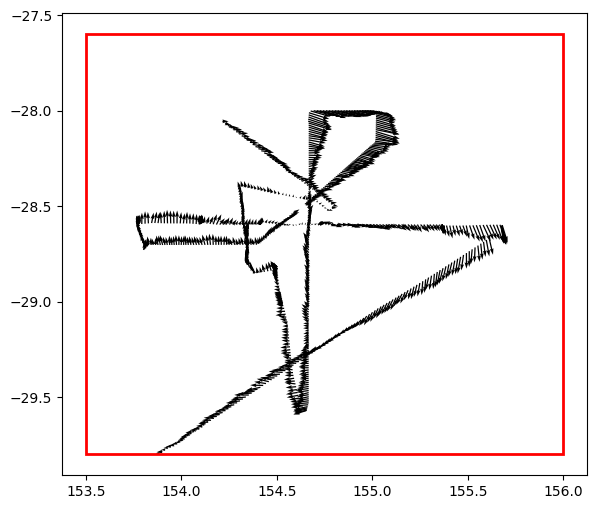

In [7]:
target_depth = adcp.Depth.value_counts().idxmax()
df = adcp[adcp.Depth == target_depth].copy()

fig, ax = plt.subplots(figsize=(8, 6))
ax.quiver(df.lon, df.lat, df.u, df.v)
ax.add_patch(Rectangle((153.5, -29.8), 156.0-153.5, -27.6-(-29.8),
                       fill=False, edgecolor='red', linewidth=2))
ax.set_aspect('equal')
plt.show()

In [4]:
adcp

,time,lat,lon,Depth,u,v,Bin Attendance %
0,2015-06-04T00:01:22Z,-28.05592,154.21479,30.4,0.266,-0.004,76
1,2015-06-04T00:01:22Z,-28.05592,154.21479,46.4,0.262,0.001,72
2,2015-06-04T00:01:22Z,-28.05592,154.21479,62.4,0.264,-0.036,56
3,2015-06-04T00:01:22Z,-28.05592,154.21479,78.4,0.346,-0.088,26
4,2015-06-04T00:01:22Z,-28.05592,154.21479,94.4,0.379,-0.098,65
...,...,...,...,...,...,...,...
39417,2015-06-07T01:56:23Z,-29.79476,153.88528,734.4,-0.100,-0.080,0
39418,2015-06-07T01:56:23Z,-29.79476,153.88528,750.4,-0.145,-0.106,0
39419,2015-06-07T01:56:23Z,-29.79476,153.88528,766.4,-0.153,-0.156,0
39420,2015-06-07T01:56:23Z,-29.79476,153.88528,782.4,-0.133,-0.154,0


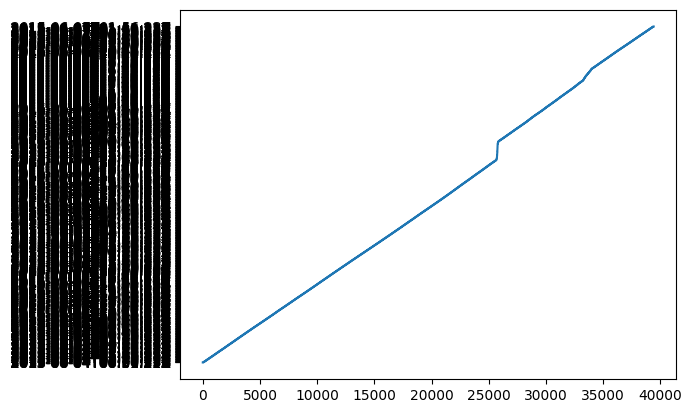

In [6]:
plt.plot(adcp.time)